# Data import
Za početak importamo datasetove. Korišteni datasetovi su preuzeti iz istraživanja pronađenog na internetu. U dokumentaciji se nalazi detaljna usporedba dobivenih rezultata s onima iz tog istraživanja, kao i poveznice na originalni istraživački rad.
Dokumentacija također sadrži detaljnu analizu svih dobivenih rezultata, kao i opis svakog koraka pri treniranju modela.

In [23]:
# import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


In [24]:
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep= ';')  # Portuguese course data
print(mat_data.head())
print(por_data.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     G

In [25]:
from sklearn.preprocessing import LabelEncoder

def preprocess_data(data):
    # Encoding the binary features
    binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                    'schoolsup', 'famsup', 'paid', 'activities', 
                    'nursery', 'higher', 'internet', 'romantic']

    label_encoder = LabelEncoder()
    for feature in binary_features:
        data[feature] = label_encoder.fit_transform(data[feature])

    # One-hot encoding the categorical features (keep all columns)
    categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']
    data = pd.get_dummies(data, columns=categorical_features)

    # Numeric features: No scaling needed for Random Forest
    numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                        'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                        'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
    return data

# Preprocess both datasets
mat_data = preprocess_data(mat_data)
por_data = preprocess_data(por_data)

In [26]:
# Separating features (X) and target (y)
X_mat = mat_data.drop('G3', axis=1)  # Features for Math data
y_mat = mat_data['G3']  # Target for Math data

X_por = por_data.drop('G3', axis=1)  # Features for Portuguese data
y_por = por_data['G3']  # Target for Portuguese data

In [27]:
# Split the data into training and testing sets (80% train, 20% test)
X_train_mat, X_test_mat, y_train_mat, y_test_mat = train_test_split(X_mat, y_mat, test_size=0.3, random_state=42)
X_train_por, X_test_por, y_train_por, y_test_por = train_test_split(X_por, y_por, test_size=0.3, random_state=42)


In [28]:
# Inicijalizacija Random Forest modela
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Treniranje modela na trening skupu
rf_model.fit(X_train_mat, y_train_mat)

# Predict the target for Math test data
y_pred_mat = rf_model.predict(X_test_mat)

# Evaluate the Math model
mse_mat = mean_squared_error(y_test_mat, y_pred_mat)
r2_mat = r2_score(y_test_mat, y_pred_mat)

# Print evaluation metrics for Math model
print("Math Data Model:")
print(f"Mean Squared Error (Math): {mse_mat}")
print(f"R-squared (Math): {r2_mat}")

Math Data Model:
Mean Squared Error (Math): 3.170138655462184
R-squared (Math): 0.855785210159081


In [29]:
# Treniranje modela na trening skupu
rf_model.fit(X_train_por, y_train_por)

# Predict the target for Math test data
y_pred_por = rf_model.predict(X_test_por)

# Evaluate the Math model
mse_por = mean_squared_error(y_test_por, y_pred_por)
r2_por = r2_score(y_test_por, y_pred_por)

# Print evaluation metrics for Math model
print("Portuguese Data Model:")
print(f"Mean Squared Error (Portuguese): {mse_por}")
print(f"R-squared (Portuguese): {r2_por}")

Portuguese Data Model:
Mean Squared Error (Portuguese): 1.5620271794871796
R-squared (Portuguese): 0.8587442067036715


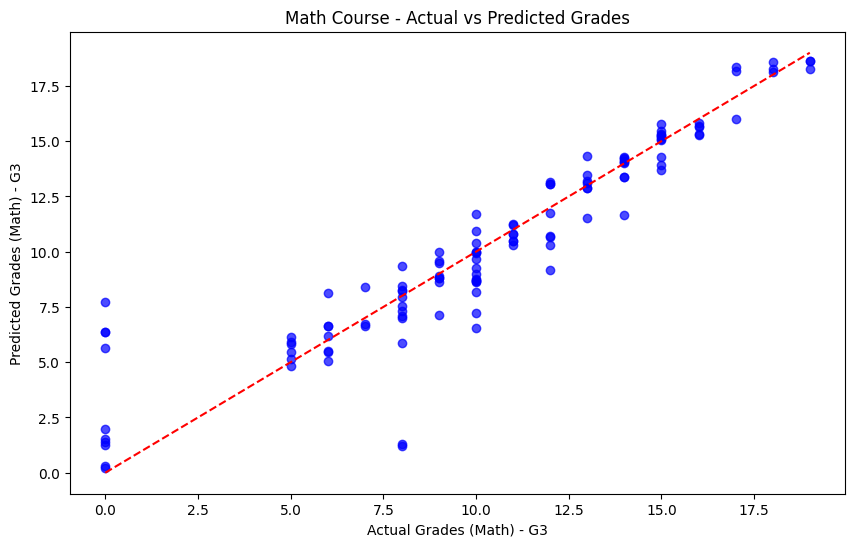

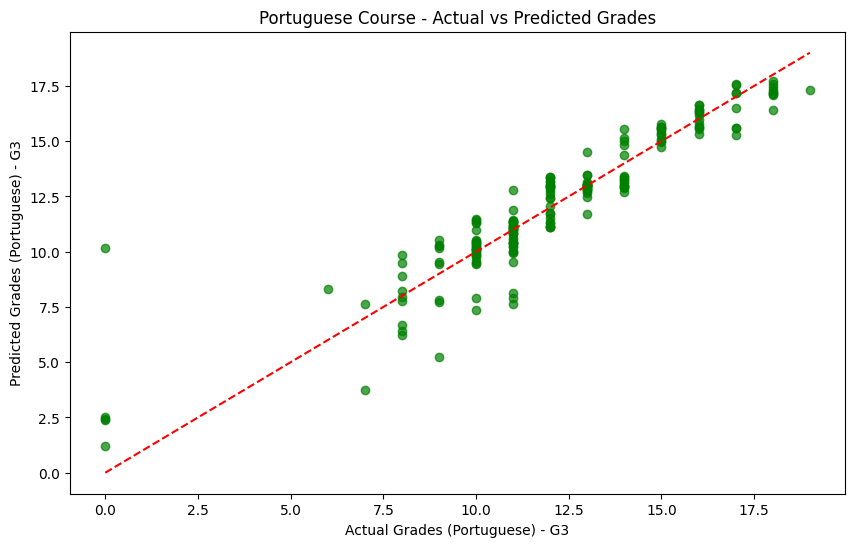

In [30]:
# Plot actual vs predicted grades for Math data
plt.figure(figsize=(10, 6))
plt.scatter(y_test_mat, y_pred_mat, alpha=0.7, color='b')
plt.plot([y_test_mat.min(), y_test_mat.max()], [y_test_mat.min(), y_test_mat.max()], color='r', linestyle='--', label='Perfect Prediction Line')
plt.xlabel("Actual Grades (Math) - G3")
plt.ylabel("Predicted Grades (Math) - G3")
plt.title("Math Course - Actual vs Predicted Grades")
plt.show()

# Plot actual vs predicted grades for Portuguese data
plt.figure(figsize=(10, 6))
plt.scatter(y_test_por, y_pred_por, alpha=0.7, color='g')
plt.plot([y_test_por.min(), y_test_por.max()], [y_test_por.min(), y_test_por.max()], color='r', linestyle='--', label='Perfect Prediction Line')
plt.xlabel("Actual Grades (Portuguese) - G3")
plt.ylabel("Predicted Grades (Portuguese) - G3")
plt.title("Portuguese Course - Actual vs Predicted Grades")
plt.show()


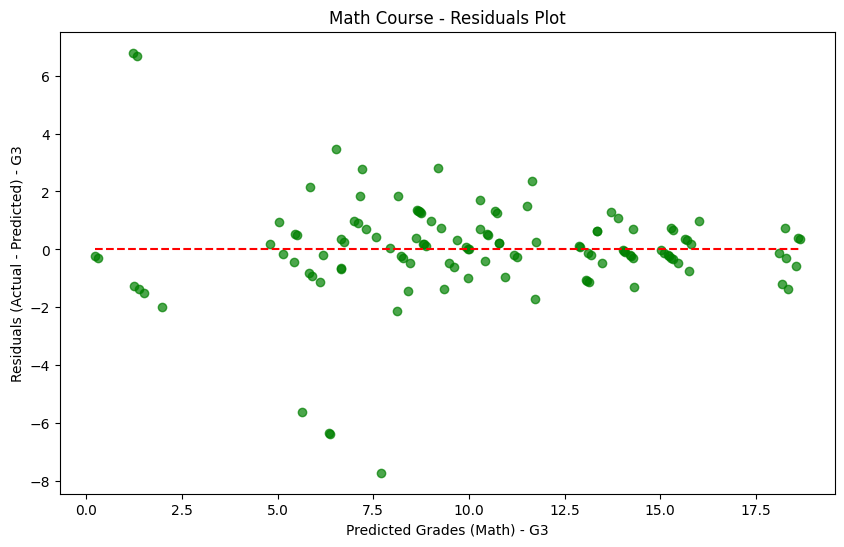

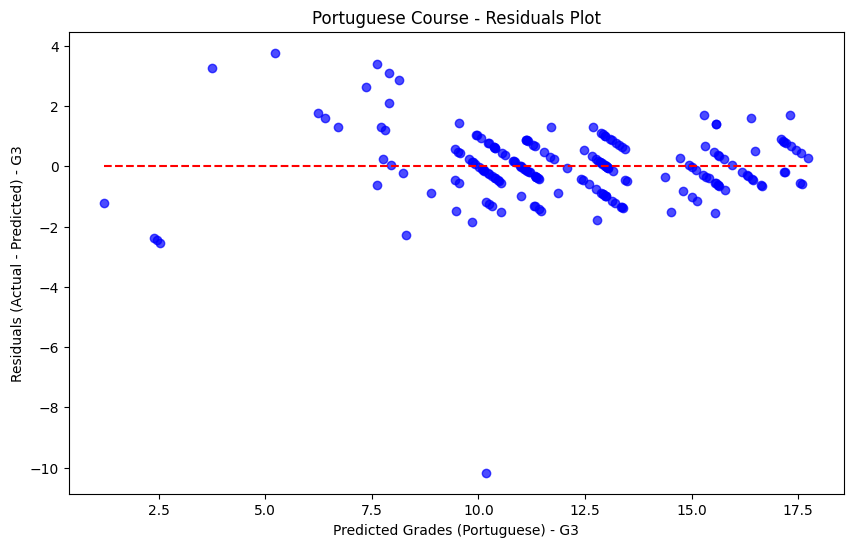

In [31]:
# Residuals Plot for Math dataset
residuals_mat = y_test_mat - y_pred_mat
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_mat, residuals_mat, alpha=0.7, color='g')
plt.hlines(y=0, xmin=y_pred_mat.min(), xmax=y_pred_mat.max(), color='r', linestyle='--')
plt.xlabel("Predicted Grades (Math) - G3")
plt.ylabel("Residuals (Actual - Predicted) - G3")
plt.title("Math Course - Residuals Plot")
plt.show()

# Residuals Plot for Portuguese dataset
residuals_por = y_test_por - y_pred_por
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_por, residuals_por, alpha=0.7, color='b')
plt.hlines(y=0, xmin=y_pred_por.min(), xmax=y_pred_por.max(), color='r', linestyle='--')
plt.xlabel("Predicted Grades (Portuguese) - G3")
plt.ylabel("Residuals (Actual - Predicted) - G3")
plt.title("Portuguese Course - Residuals Plot")
plt.show()


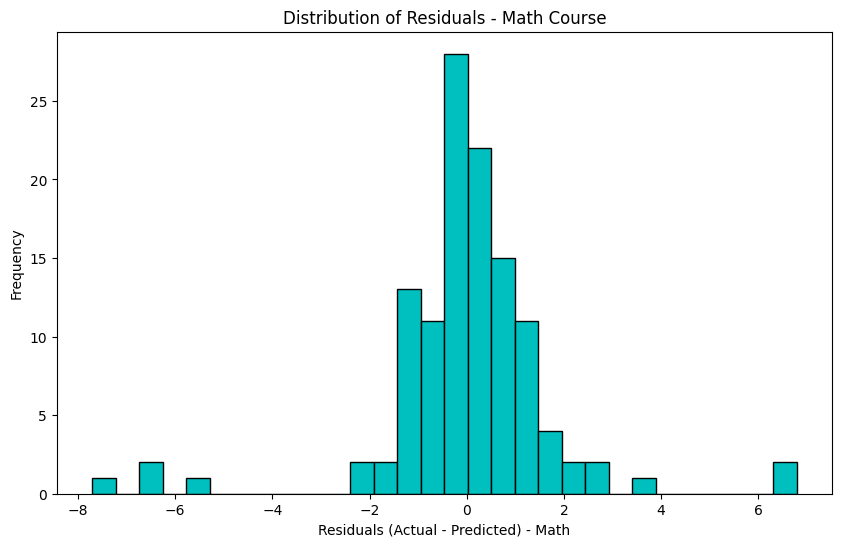

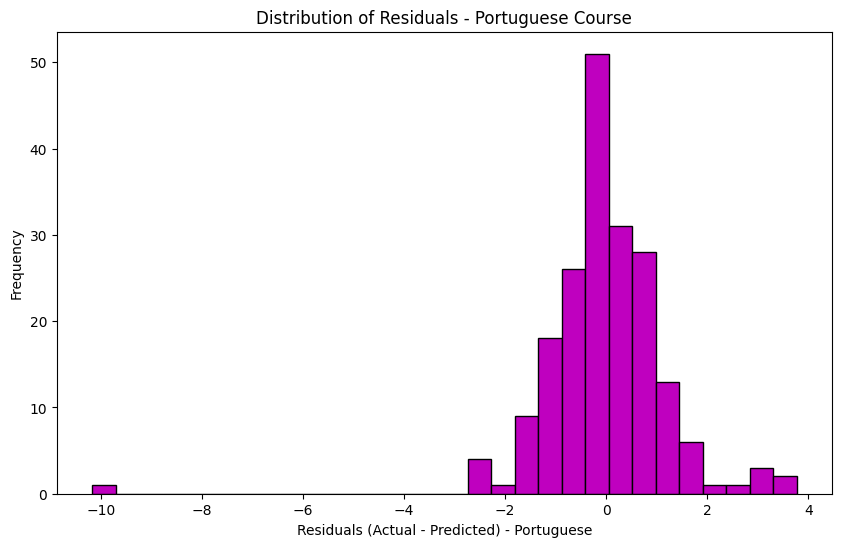

In [32]:
# Distribution of Residuals for Math dataset
plt.figure(figsize=(10, 6))
plt.hist(residuals_mat, bins=30, color='c', edgecolor='black')
plt.xlabel("Residuals (Actual - Predicted) - Math")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals - Math Course")
plt.show()

# Distribution of Residuals for Portuguese dataset
plt.figure(figsize=(10, 6))
plt.hist(residuals_por, bins=30, color='m', edgecolor='black')
plt.xlabel("Residuals (Actual - Predicted) - Portuguese")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals - Portuguese Course")
plt.show()


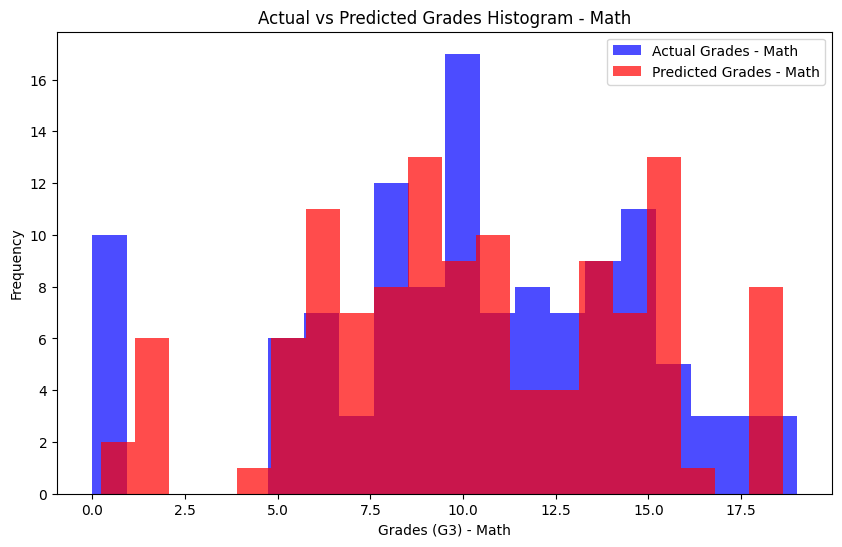

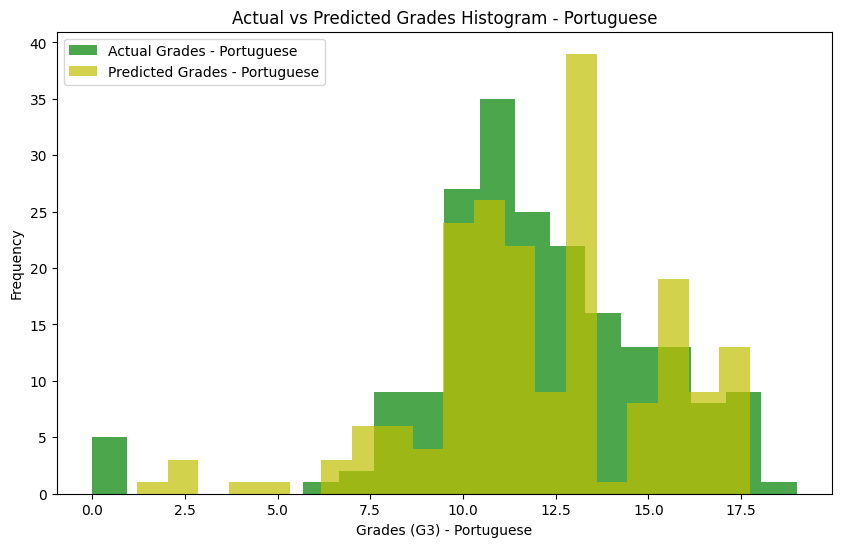

In [33]:
# Actual vs Predicted Grades Histogram for Math dataset
plt.figure(figsize=(10, 6))
plt.hist(y_test_mat, bins=20, alpha=0.7, label='Actual Grades - Math', color='b')
plt.hist(y_pred_mat, bins=20, alpha=0.7, label='Predicted Grades - Math', color='r')
plt.xlabel("Grades (G3) - Math")
plt.ylabel("Frequency")
plt.title("Actual vs Predicted Grades Histogram - Math")
plt.legend()
plt.show()

# Actual vs Predicted Grades Histogram for Portuguese dataset
plt.figure(figsize=(10, 6))
plt.hist(y_test_por, bins=20, alpha=0.7, label='Actual Grades - Portuguese', color='g')
plt.hist(y_pred_por, bins=20, alpha=0.7, label='Predicted Grades - Portuguese', color='y')
plt.xlabel("Grades (G3) - Portuguese")
plt.ylabel("Frequency")
plt.title("Actual vs Predicted Grades Histogram - Portuguese")
plt.legend()
plt.show()

# Optimizacija